# Loss-based difficulty: analysis

Looks at `data/features/alma_train_loss.csv` (from `scripts/compute_loss.py`): the per-token
loss of every ALMA training pair under the **pretrained** M2M-100.

Questions:
1. What does the `loss_mean` distribution look like (where would a "hard" cutoff go)?
2. How much does it overlap with the difficulty we already have (length, `rarity_mean`)?
3. What are the highest-loss pairs: genuinely hard, or noise (misaligned / bad references)?
4. What would a cutoff do to the sampling weights?

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Paths are relative to the repository root.
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, "scripts")
from data_utils import MAX_LEN, all_cells, assign_bins, read_jsonl

STEM = "alma_train"
LOSS_PATH = Path(f"data/features/{STEM}_loss.csv")

loss = pd.read_csv(LOSS_PATH)
feats = assign_bins(pd.read_csv(f"data/features/{STEM}.csv"))
text = pd.DataFrame(read_jsonl(f"data/processed/{STEM}.jsonl"))[["id", "zh", "en"]]

df = (loss.merge(feats, on="id", validate="one_to_one")
          .merge(text, on="id", validate="one_to_one"))
df["len_ratio"] = df["tgt_len"] / df["src_len"]   # target / source subwords
print(f"{len(loss)} loss rows, {len(feats)} feature rows, {len(df)} merged")
assert len(df) == len(loss) == len(feats), "ids do not match between files"

15362 loss rows, 15362 feature rows, 15362 merged


## 1. Distribution

,loss_mean,loss_sum,n_tgt
count,15362.000,15362.000,15362.000
mean,1.987,82.510,41.665
std,0.744,57.198,23.753
min,0.304,4.828,3.000
1%,0.672,12.532,9.000
10%,1.117,28.517,18.000
25%,1.458,44.041,26.000
50%,1.900,68.855,37.000
75%,2.408,104.645,51.000
80%,2.552,116.144,55.000


pairs with target truncated at MAX_LEN (256): 0


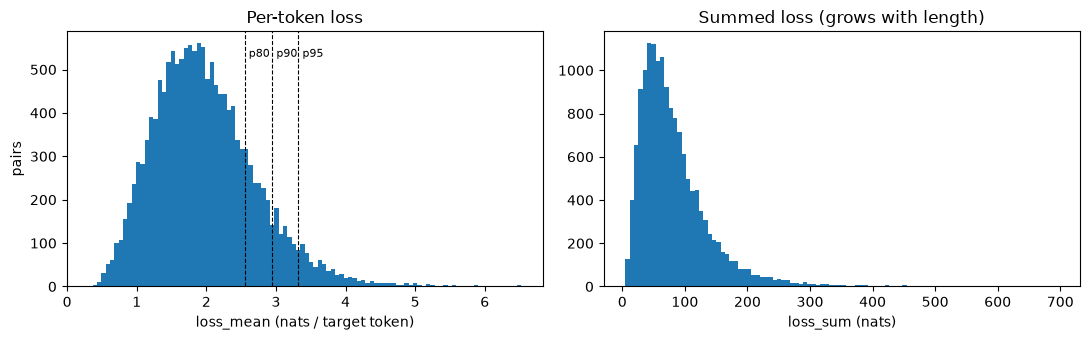

In [3]:
pcts = [0.01, 0.1, 0.25, 0.5, 0.75, 0.8, 0.9, 0.95, 0.99]
display(df[["loss_mean", "loss_sum", "n_tgt"]].describe(percentiles=pcts).round(3))
print(f"pairs with target truncated at MAX_LEN ({MAX_LEN}): {(df['n_tgt'] >= MAX_LEN).sum()}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(df["loss_mean"], bins=100)
for q in [0.8, 0.9, 0.95]:
    v = df["loss_mean"].quantile(q)
    axes[0].axvline(v, ls="--", c="k", lw=0.8)
    axes[0].text(v, axes[0].get_ylim()[1] * 0.9, f" p{int(q*100)}", fontsize=8)
axes[0].set(xlabel="loss_mean (nats / target token)", ylabel="pairs", title="Per-token loss")
axes[1].hist(df["loss_sum"], bins=100)
axes[1].set(xlabel="loss_sum (nats)", title="Summed loss (grows with length)")
plt.tight_layout()

## 2. Overlap with the existing difficulty features

Spearman (rank) correlation is the main number: we only care whether the *ordering* of pairs
agrees, and it is robust to the long tail. If `loss_mean` vs `rarity_mean` is high (say > 0.7),
the loss condition mostly repeats the rarity condition.

In [4]:
cols = ["loss_mean", "loss_sum", "rarity_mean", "rarity_max", "src_len", "tgt_len", "len_ratio", "n_unseen"]
spearman = df[cols].corr(method="spearman")
display(spearman.round(2).style.background_gradient(cmap="RdBu_r", vmin=-1, vmax=1))
print("Pearson loss_mean vs rarity_mean:", round(df["loss_mean"].corr(df["rarity_mean"]), 3))

,loss_mean,loss_sum,rarity_mean,rarity_max,src_len,tgt_len,len_ratio,n_unseen
loss_mean,1.000000,0.570000,0.110000,0.120000,0.030000,0.010000,-0.050000,0.010000
loss_sum,0.570000,1.000000,0.190000,0.310000,0.740000,0.800000,0.220000,0.090000
rarity_mean,0.110000,0.190000,1.000000,0.510000,0.150000,0.150000,0.050000,0.300000
rarity_max,0.120000,0.310000,0.510000,1.000000,0.400000,0.300000,-0.180000,0.500000
src_len,0.030000,0.740000,0.150000,0.400000,1.000000,0.900000,-0.110000,0.210000
tgt_len,0.010000,0.800000,0.150000,0.300000,0.900000,1.000000,0.300000,0.110000
len_ratio,-0.050000,0.220000,0.050000,-0.180000,-0.110000,0.300000,1.000000,-0.190000
n_unseen,0.010000,0.090000,0.300000,0.500000,0.210000,0.110000,-0.190000,1.000000


Pearson loss_mean vs rarity_mean: 0.083


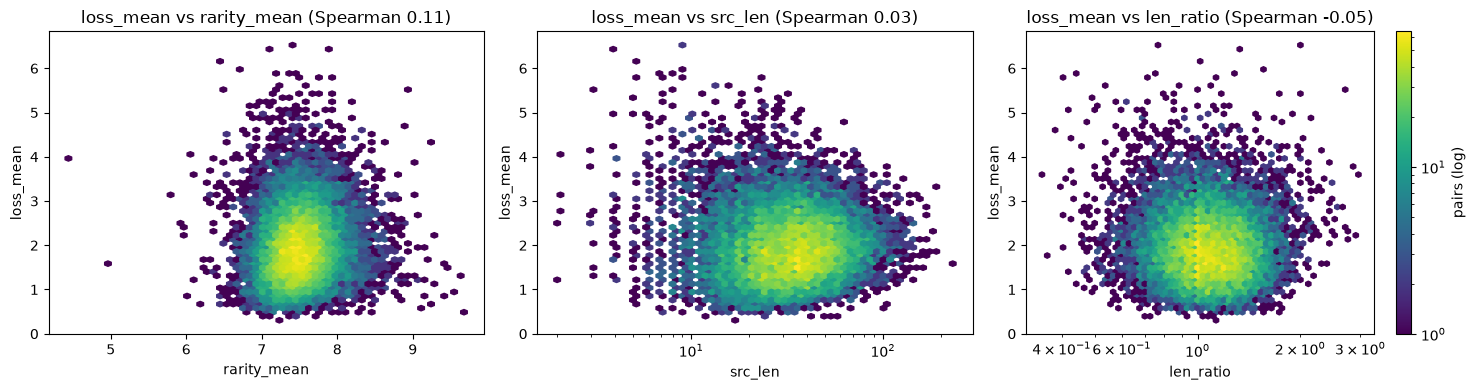

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, x in zip(axes, ["rarity_mean", "src_len", "len_ratio"]):
    hb = ax.hexbin(df[x], df["loss_mean"], gridsize=60, bins="log", mincnt=1,
                   xscale="log" if x != "rarity_mean" else "linear")
    rho = df[x].rank().corr(df["loss_mean"].rank())  # Spearman without scipy
    ax.set(xlabel=x, ylabel="loss_mean", title=f"loss_mean vs {x} (Spearman {rho:.2f})")
plt.colorbar(hb, ax=axes[-1], label="pairs (log)")
plt.tight_layout()

Mean `loss_mean` per difficulty cell (rows = length bin, columns = rarity bin), and pair counts.

In [6]:
by_cell = df.groupby(["length_bin", "rarity_bin"])["loss_mean"].agg(["mean", "median", "count"])
order = [c.split("/")[0] for c in all_cells()[::2]]
display(by_cell["mean"].unstack().loc[order].round(3))
display(by_cell["count"].unstack().loc[order])

rarity_bin,rare,typical
length_bin,,
short,2.283,2.166
mid_short,2.167,1.911
mid_long,2.013,1.956
long,2.104,2.053


rarity_bin,rare,typical
length_bin,,
short,252,1304
mid_short,603,4758
mid_long,731,6155
long,195,1364


Do the "hard by loss" pairs and the "rare" pairs pick out the same sentences?
Here "hard" = top 10% by `loss_mean`, so both groups are about 10% of the pool.

In [7]:
HARD_Q = 0.90
cut = df["loss_mean"].quantile(HARD_Q)
df["hard"] = df["loss_mean"] > cut
display(pd.crosstab(df["hard"], df["rarity_bin"], margins=True))
both = (df["hard"] & (df["rarity_bin"] == "rare")).sum()
either = (df["hard"] | (df["rarity_bin"] == "rare")).sum()
print(f"cutoff p{int(HARD_Q*100)} = {cut:.3f}")
print(f"Jaccard(hard, rare) = {both / either:.2f}  (random overlap would be about 0.05)")
print(f"P(rare | hard) = {both / df['hard'].sum():.2f}   P(rare) = {(df['rarity_bin'] == 'rare').mean():.2f}")

rarity_bin,rare,typical,All
hard,,,
False,1517,12308,13825
True,264,1273,1537
All,1781,13581,15362


cutoff p90 = 2.949
Jaccard(hard, rare) = 0.09  (random overlap would be about 0.05)
P(rare | hard) = 0.17   P(rare) = 0.12


## 3. Highest-loss pairs

Read these. If most look misaligned, partially translated or wrong, upsampling the top would mostly
upsample noise, and we should drop the extreme tail (e.g. top 1%) or put the cutoff band lower.

In [8]:
pd.set_option("display.max_colwidth", 200)
show = ["id", "loss_mean", "n_tgt", "src_len", "tgt_len", "rarity_mean", "zh", "en"]
display(df.nlargest(30, "loss_mean")[show].round(2))

,id,loss_mean,n_tgt,src_len,tgt_len,rarity_mean,zh,en
187,alma-train-000187,6.52,9,9,7,7.44,自由体操动作惊艳。,Jaw-dropping on floor.
2506,alma-train-002508,6.47,10,4,8,7.09,作出新贡献,all-round modern socialist nation.
2414,alma-train-002414,6.46,14,9,12,7.89,下面请看联播快讯。,Xinwen Lianbo news bulletins are next.
4334,alma-train-004354,6.19,7,5,5,6.49,胜在风情,Reputed for Local Custom
4041,alma-train-004050,5.97,16,9,14,6.74,发生枪击，造成三人死亡,"on the evening of November 1 local time, this morning Beijing time."
2367,alma-train-002367,5.89,8,8,6,7.45,和地区事务中的沟通协调,such as the SCO.
10995,alma-train-011037,5.87,11,7,9,7.40,英国脱欧困难重重,Brexit can get plenty more toxic from here
2771,alma-train-002777,5.85,6,9,4,7.19,武装头脑，指导实践。,and their policies.
967,alma-train-000967,5.79,29,24,27,7.90,而他和女儿参加“爸爸去哪”等综艺节目，更是让他赚足了眼球。,"The once gold generation Yang Wei, Li Xiaopeng and Chen Yibing all participated in a variety of variety show."
3878,alma-train-003887,5.79,4,5,2,7.53,合影留念,Group photo


Lowest-loss pairs, for contrast (often very short, formulaic, or memorised).

In [9]:
display(df.nsmallest(15, "loss_mean")[show].round(2))

,id,loss_mean,n_tgt,src_len,tgt_len,rarity_mean,zh,en
2350,alma-train-002350,0.30,21,17,19,7.22,欧亚经济联盟和一带一路倡议具有互补性。,The Eurasian Economic Union and the Belt and Road Initiative are complementary.
13635,alma-train-013679,0.36,40,55,38,7.11,抗议还发生在巴黎、保加利亚的索非亚、立陶宛的维尔纽斯、马耳他的瓦莱塔、爱沙尼亚的塔林以及苏格兰的爱丁堡和格拉斯哥。,"Protests also took place in Paris, Sofia in Bulgaria, Vilnius in Lithuania, Valetta in Malta, Tallinn in Estonia, and Edinburgh and Glasgow in Scotland."
8840,alma-train-008881,0.40,38,50,36,7.37,“这又是一个令人难过的证据，说明国会需要出手采取行动，保护社交媒体用户的隐私和安全 ， ” 民主党参议员Mark Warner在一份声明中称。,"""This is another sad evidence that the Congress needs to take action to protect the privacy and security of social media users,"" Democratic Senator Mark Warner said in a statement."
9287,alma-train-009328,0.41,66,60,64,7.73,9月，油价已经有过两次上调：9月3日，汽油上调180元/吨，柴油上调170元/吨；9月17日，汽油上调145元/吨，柴油上调145元/吨。,"In September, oil prices have been raised twice: on September 3, gasoline was raised by 180 yuan / ton, diesel was raised by 170 yuan / ton; on September 17, gasoline was raised by 145 yuan / ton,..."
13600,alma-train-013644,0.42,24,24,22,7.43,这些代理人负责根据《巴基斯坦宪法》第 247 条提供政府和司法服务。,These agents are responsible for providing government and judicial services under Article 247 of the Pakistani Constitution.
11386,alma-train-011428,0.43,48,42,46,6.99,这份协议的其他签约国，英国、中国、法国、德国和俄罗斯，一直试图挽救该协议，但德黑兰一再指责欧洲做得不够多。,"The other signatories of the agreement, Britain, China, France, Germany, and Russia, have been trying to save the agreement, but Tehran has repeatedly accused Europe of not doing enough."
3119,alma-train-003126,0.43,27,24,25,7.45,报告对去年12月访问首尔的1045名外国游客参与问卷调查的结果进行了分析。,"The report analyzed the results of a survey of 1,045 foreign tourists who visited Seoul in December last year."
11865,alma-train-011908,0.44,16,12,14,6.96,它们需要整个国际社会的长期关注和投资。,They need long-term attention and investment from the entire international community.
12195,alma-train-012238,0.45,40,26,38,7.02,在过去40年里，中国是联合国工作的关键参与者，成为国际合作和多边主义的支柱。,"In the past 40 years, China has been a key participant in the work of the United Nations, and has become a pillar of international cooperation and multilateralism."
2356,alma-train-002356,0.46,24,16,22,7.54,已经成为维护地区安全稳定、促进共同发展繁荣的重要平台。,has become an important platform for maintaining regional security and stability and promoting common development and prosperity.


A random sample from the band that would actually get upsampled with a p90 cutoff but no
noise filter (p90 to p99). This is a fairer picture than the extreme top.

In [10]:
lo, hi = df["loss_mean"].quantile([0.90, 0.99])
band = df[(df["loss_mean"] > lo) & (df["loss_mean"] <= hi)]
display(band.sample(20, random_state=0)[show].round(2))

,id,loss_mean,n_tgt,src_len,tgt_len,rarity_mean,zh,en
6081,alma-train-006115,3.44,26,22,24,7.02,球向球门右上角偏移时，在禁区上方飞得很高。,The attempt sailed high above the box as it drifted toward the right top corner of the net.
9832,alma-train-009873,3.13,90,58,88,7.65,最终，大满贯得主丁宁4:0力克主场作战的队友朱雨玲，时隔四年再次登上女乒世界杯冠军宝座，这也是中国女乒第21次摘下该项赛事桂冠。,"Ding Ning, the Grand Slam winner, finally secured an impressive 4-0 victory over her teammate Zhu Yuling, who was the host, and won the golden medal again in the ITTF Women's World Cup after four ..."
4011,alma-train-004020,4.16,9,3,7,7.25,作出贡献,Sustainable Development goals.
14162,alma-train-014206,2.95,34,27,32,7.22,溪降时要进入峡谷的底部，峡谷可以是干涸的，也可以有很深的水。,"Canyoning (or: canyoneering) is about going in a bottom of a canyon, which is either dry or full of water."
12795,alma-train-012838,3.45,24,20,22,7.55,伊朗被证实研发先进离心机 进一步中止履行伊核协议,"Iran upgrades nuclear infrastructure, a further step to scale down its commitments to the nuclear deal"
1263,alma-train-001263,3.07,63,80,61,7.60,银牌对于被击败的英国队而言也算是一个不小的安慰，这块银牌是英国代表团当天获得的第三块银牌。这一成绩足以让英国橄榄球队感到骄傲：他们在首次进入奥运会的七人制橄榄球赛上一路击败了新西兰、阿根廷和南非。,Defeat came with the non-too shabby consolation of silver - Britain's third of the day - and they could be proud of their efforts in the inaugural Olympic 7s tournament in which they beat New Zeal...
1662,alma-train-001662,3.50,39,37,37,7.98,另一个帖子直指酒店“真不要脸”，并且指出这家位于著名的库达姆大街的大街就在一座犹太教会堂附近。,"""Shame on you,"" another post stated, pointing out that the hotel, located in the noble Kurfurstendamm street stands near a synagogue."
1438,alma-train-001438,3.42,39,30,37,7.80,作为一名美食家，罗斯福总统喜欢第五大道的美食，比如鹅肝酱和马里兰炖水鱼。,"A gourmand, President Roosevelt had a taste for fancy Fifth Avenue foods like pâté de foie gras and Maryland terrapin soup."
4893,alma-train-004914,3.42,37,28,35,7.31,另外，有读者多次爆料网购被骗，消费者在非正规网站购物时需多留心。,"Elsewhere, readers had repeatedly reported having been cheated while shopping online. Shoppers should be on their guard when shopping at unofficial websites."
3577,alma-train-003585,3.02,34,34,32,7.76,该决策制定之前一年，令人震惊的欧盟全民公投让英镑暴跌，八月份利率下调至 0.25%。,"The decision comes a year after rates were cut to 0.25% last August following the shock EU referendum vote, which sent the pound slumping."


### Simple noise flags by loss band

Rough automatic checks (none of them is a proof of noise):
- `cjk_in_en`: the English side still contains Chinese characters
- `odd_ratio`: target/source subword ratio outside [0.5, 2.5]
- `very_short`: source of at most 3 subwords

In [11]:
df["cjk_in_en"] = df["en"].str.contains("[一-鿿]")  # CJK unified ideographs
df["odd_ratio"] = ~df["len_ratio"].between(0.5, 2.5)
df["very_short"] = df["src_len"] <= 3
bands = pd.cut(df["loss_mean"].rank(pct=True), [0, 0.5, 0.8, 0.9, 0.95, 0.99, 1.0],
               labels=["0-50%", "50-80%", "80-90%", "90-95%", "95-99%", "top 1%"])
flags = ["cjk_in_en", "odd_ratio", "very_short"]
display((df.groupby(bands, observed=True)[flags].mean() * 100).round(1).add_suffix(" %"))

,cjk_in_en %,odd_ratio %,very_short %
loss_mean,,,
0-50%,0.0,0.2,0.0
50-80%,0.0,0.3,0.1
80-90%,0.0,0.7,0.2
90-95%,0.0,0.4,0.1
95-99%,0.0,1.0,0.5
top 1%,0.0,5.8,0.6


## 4. What a cutoff would do to sampling

`train.py` would split pairs into easy / hard and use `balanced_weights(..., cap)`: each group gets
half the probability, but no pair more than `cap` (3) times its uniform weight. Below: for a few
cutoffs, the share of hard pairs in the pool and in the drawn batches, on the size-1000 subsets.

In [12]:
def balanced_weights(groups, cap=3.0):
    # Copy of train.py's balanced_weights (train.py imports torch).
    n_groups = groups.nunique()
    group_size = groups.map(groups.value_counts())
    return ((len(groups) / n_groups) / group_size).clip(upper=cap)

rows = []
for q in [0.80, 0.90, 0.95]:
    cut = df["loss_mean"].quantile(q)       # fixed edge from the FULL pool, like rarity's 7.9
    for size in ["1000", "5000", "full"]:
        for seed in [0, 1, 2]:
            if size == "full":
                sub = df
            else:
                ids = Path(f"data/subsets/seed{seed}_n{size}.txt").read_text().split()
                sub = df.set_index("id").loc[ids]
            hard = sub["loss_mean"] > cut
            w = balanced_weights(hard)
            rows.append({"cutoff": f"p{int(q*100)} ({cut:.2f})", "size": size, "seed": seed,
                         "n_hard": int(hard.sum()), "hard % in pool": 100 * hard.mean(),
                         "hard % in batches": 100 * w[hard].sum() / w.sum(),
                         "max weight": w.max()})
            if size == "full":
                break
display(pd.DataFrame(rows).groupby(["cutoff", "size"], sort=False)
        [["n_hard", "hard % in pool", "hard % in batches", "max weight"]].mean().round(1))

n_hard  hard % in pool  hard % in batches  max weight
cutoff     size                                                       
p80 (2.55) 1000   212.7            21.3               50.0         2.4
           5000  1012.0            20.2               50.0         2.5
           full  3072.0            20.0               50.0         2.5
p90 (2.95) 1000   111.0            11.1               40.0         3.0
           5000   512.7            10.3               38.1         3.0
           full  1537.0            10.0               37.5         3.0
p95 (3.32) 1000    49.7             5.0               22.9         3.0
           5000   258.7             5.2               23.7         3.0
           full   769.0             5.0               23.1         3.0

## Notes for the decision

- Correlation with `rarity_mean` / length: _fill in_
- What the top tail looks like (noise or hard): _fill in_
- Chosen cutoff and whether to drop the top 1%: _fill in_